# NumPy Beyond Syntax
## Memory, Vectorization, Performance and Array Backends

**Practical 3 — approximately 115 minutes**

An `ndarray` is not "a list, but faster". It is

$$\textbf{ndarray} \;=\; \text{typed buffer} \;+\; \text{shape} \;+\; \text{strides} \;+\; \text{operations}$$

and speed is not a matter of Python tricks:

$$\text{performance} \;\approx\; \text{algorithm} \;+\; \text{data movement} \;+\; \text{memory layout} \;+\; \text{compiled kernel}$$

### Learning outcomes

After this session you should be able to:

1. read `shape`, `dtype`, `strides` and `flags`, and predict from them how an array behaves in memory
2. explain *why* a vectorized expression is fast, and recognise when it is still wasteful
3. tell a view from a copy before running the code
4. choose a memory layout that lets BLAS/LAPACK do its job
5. measure performance instead of guessing at it
6. carry the same computational model onto another array backend, and argue when that is worth doing

### Requirements

`numpy` and `matplotlib` only. Parts 1–9 run on any CPU. Part 10 is optional and each subsection skips itself if the library is absent.

### Running the timings

Every benchmark in this notebook is measured on **your** machine when you run it. Numbers will differ between laptops, between runs and between library builds. Treat the ratio as evidence about the execution path, never as a constant to memorise.

### Session plan

| Time | Part | What you should discover |
|---|---|---|
| 0–10 min | 1. ndarray as a memory object | buffer, dtype, shape, strides, flags |
| 10–30 min | 2–4. vectorization, broadcasting, ufuncs | why bulk operations work, where temporaries appear |
| 30–50 min | 5–6. views, copies, indexing | aliasing, fancy indexing, scatter and gather |
| 50–70 min | 7. layout and BLAS | C/F order, alignment, `@`, SVD, runtime introspection |
| 70–85 min | 8. stride tricks and specialized arrays | sliding windows, structured dtypes, masks |
| 85–100 min | 9. random, testing, profiling | `Generator`, tolerances, `%timeit`, line profiling |
| 100–115 min | 10. alternative backends | CuPy, JAX, dpnp, ArrayFire, migration patterns |

Parts 8.2 and 8.3 (structured dtypes, masked arrays) are reference-depth. The core to work through carefully is broadcasting, temporaries, views and copies, advanced indexing, strides and layout, BLAS and profiling.

## 0. Environment

In [4]:
import sys
import platform
import timeit

import numpy as np
import matplotlib.pyplot as plt

print("Python: ", sys.version.split()[0])
print("NumPy:  ", np.__version__)
print("Platform:", platform.platform())

Python:  3.12.3
NumPy:   2.5.3
Platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39


In [6]:
# What compiled machinery is NumPy actually sitting on?
# Look for the SIMD baseline/dispatch entries and the BLAS/LAPACK section.
if hasattr(np, "show_runtime"):
    np.show_runtime()
else:
    np.show_config()

[{'numpy_version': '2.5.3',
  'python': '3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]',
  'uname': uname_result(system='Linux', node='STAR-PLATINUM', release='6.6.87.2-microsoft-standard-WSL2', version='#1 SMP PREEMPT_DYNAMIC Thu Jun  5 18:30:46 UTC 2025', machine='x86_64')},
 {'simd_extensions': {'baseline': ['X86_V2'],
                      'found': ['X86_V3'],
                      'not_found': ['X86_V4', 'AVX512_ICL', 'AVX512_SPR']}},
 {'ignore_floating_point_errors_in_matmul': False},
 {'architecture': 'Haswell',
  'filepath': '/home/roaffix/Workspace/LEC/SIS/.venv/lib/python3.12/site-packages/numpy.libs/libscipy_openblas64_-f48b354e.so',
  'internal_api': 'openblas',
  'num_threads': 24,
  'prefix': 'libscipy_openblas',
  'threading_layer': 'pthreads',
  'user_api': 'blas',
  'version': '0.3.34.106.0'}]


---
## 1. The ndarray as a memory object

An array has two parts: a flat block of bytes, and metadata describing how to walk it.

```
view                          buffer
┌───────────────┐            ┌────────────────────────┐
│ shape         │            │ 0 1 2 3 4 5 6 7 8 9 …  │
│ dtype         │───────────►│                        │
│ strides       │            └────────────────────────┘
└───────────────┘                       ▲
                              base ─────┘
```

`strides` are **byte** steps, one per dimension. The address of element `(i, j)` is
`data + i*strides[0] + j*strides[1]`. If you have written C or C++, you already know this pattern.

In [9]:
def describe_array(a, name="a"):
    """Print the full memory identity of an array."""
    print(
        f"{name}: shape={a.shape}, dtype={a.dtype}, itemsize={a.itemsize}, "
        f"strides={a.strides}, nbytes={a.nbytes}"
    )
    print(
        f"  C_CONTIGUOUS={a.flags.c_contiguous}, F_CONTIGUOUS={a.flags.f_contiguous}, "
        f"ALIGNED={a.flags.aligned}, OWNDATA={a.flags.owndata}, "
        f"WRITEABLE={a.flags.writeable}"
    )
    base = type(a.base).__name__ if a.base is not None else None
    print(f"  data pointer=0x{a.ctypes.data:x}, base={base}")

In [10]:
a = np.arange(12, dtype=np.float64).reshape(3, 4)
describe_array(a, "a")

a: shape=(3, 4), dtype=float64, itemsize=8, strides=(32, 8), nbytes=96
  C_CONTIGUOUS=True, F_CONTIGUOUS=False, ALIGNED=True, OWNDATA=False, WRITEABLE=True
  data pointer=0x1ae47ba0, base=ndarray


**Question.** This `(3, 4)` `float64` array reports strides `(32, 8)`. Where do 32 and 8 come from,
and what would they become for a `(3, 4)` array of `float32`?

In [11]:
# Metadata-only transformations: same buffer, different walk.
describe_array(a.T, "a.T")
describe_array(a[:, ::2], "a[:, ::2]")
describe_array(a.astype(np.float32), "a.astype(float32)")

a.T: shape=(4, 3), dtype=float64, itemsize=8, strides=(8, 32), nbytes=96
  C_CONTIGUOUS=False, F_CONTIGUOUS=True, ALIGNED=True, OWNDATA=False, WRITEABLE=True
  data pointer=0x1ae47ba0, base=ndarray
a[:, ::2]: shape=(3, 2), dtype=float64, itemsize=8, strides=(32, 16), nbytes=48
  C_CONTIGUOUS=False, F_CONTIGUOUS=False, ALIGNED=True, OWNDATA=False, WRITEABLE=True
  data pointer=0x1ae47ba0, base=ndarray
a.astype(float32): shape=(3, 4), dtype=float32, itemsize=4, strides=(16, 4), nbytes=48
  C_CONTIGUOUS=True, F_CONTIGUOUS=False, ALIGNED=True, OWNDATA=True, WRITEABLE=True
  data pointer=0x1c017650, base=None


Note which of the three above has `OWNDATA=True`. That single flag already tells you which
operation paid for a copy.

---
## 2. Vectorization is delegation

A NumPy expression does not make Python's loop faster. It moves the loop out of Python entirely,
into a compiled kernel that walks a homogeneous buffer. NumPy can additionally select
SIMD-optimized inner loops depending on the CPU features it detects at import time.

In [12]:
rng = np.random.default_rng(2026)
x = rng.standard_normal(300_000)


def python_polynomial(values):
    return [v * v + 2.0 * v + 1.0 for v in values]


def numpy_polynomial(values):
    return values * values + 2.0 * values + 1.0


# Correctness first, speed second.
np.testing.assert_allclose(np.asarray(python_polynomial(x)), numpy_polynomial(x))

t_py = min(timeit.repeat(lambda: python_polynomial(x), number=1, repeat=3))
t_np = min(timeit.repeat(lambda: numpy_polynomial(x), number=10, repeat=5)) / 10

print(f"Python list comprehension: {t_py * 1e3:8.2f} ms")
print(f"NumPy expression:          {t_np * 1e3:8.2f} ms")
print(f"Ratio on this machine:     {t_py / t_np:8.1f}x")

Python list comprehension:    34.28 ms
NumPy expression:              0.32 ms
Ratio on this machine:        107.0x


**Do not memorise the ratio.** It depends on the machine, the array size, the dtype and the build.
The question worth answering is *why the two execution paths differ*: one dispatches a Python
object method per element, the other runs one compiled loop over a typed buffer.

---
## 3. Broadcasting

Broadcasting compares shapes from the **trailing** dimension backwards. Two dimensions are
compatible when they are equal or one of them is 1. The size-1 dimension is conceptually stretched,
and normally no tiled copy is materialised — internally the stretched axis is walked with stride 0.

A useful real example is per-channel normalization of an image stored as `(H, W, C)`.

In [13]:
image = rng.integers(0, 256, size=(240, 320, 3), dtype=np.uint8).astype(np.float32)

mean_rgb = image.mean(axis=(0, 1), keepdims=True)   # (1, 1, 3)
std_rgb = image.std(axis=(0, 1), keepdims=True)     # (1, 1, 3)

normalized = (image - mean_rgb) / std_rgb

print("image:      ", image.shape)
print("mean_rgb:   ", mean_rgb.shape)
print("std_rgb:    ", std_rgb.shape)
print("normalized: ", normalized.shape)
print("channel means after normalization:", normalized.mean(axis=(0, 1)).round(5))
print("channel stds after normalization: ", normalized.std(axis=(0, 1)).round(5))

image:       (240, 320, 3)
mean_rgb:    (1, 1, 3)
std_rgb:     (1, 1, 3)
normalized:  (240, 320, 3)
channel means after normalization: [-0. -0.  0.]
channel stds after normalization:  [1.00001 0.99997 1.00001]


`keepdims=True` is not cosmetic. It keeps the singleton axis so that the broadcast geometry is
stated explicitly in the shape rather than reconstructed by the reader.

This one example carries axes, reductions, `keepdims`, broadcasting and image tensors at once.

---
## 4. Where vectorization becomes expensive

> **Vectorized does not automatically mean efficient.**

Squared pairwise distances between $N$ points in $\mathbb{R}^D$ can be written by broadcasting to an
$(N, N, D)$ intermediate. That intermediate is real memory. The Gram identity

$$\lVert x - y \rVert^2 = \lVert x \rVert^2 + \lVert y \rVert^2 - 2\,x^\top y$$

computes the same matrix through a single matrix product, with an $(N, N)$ result and no $(N, N, D)$
temporary at all.

In [14]:
def pairwise_sqdist_broadcast(X):
    diff = X[:, None, :] - X[None, :, :]      # (N, N, D) temporary
    return np.sum(diff * diff, axis=-1)


def pairwise_sqdist_gram(X):
    sq = np.sum(X * X, axis=1, keepdims=True)  # (N, 1)
    return np.maximum(sq + sq.T - 2.0 * (X @ X.T), 0.0)


# What the broadcast form would cost at realistic scale.
N, D = 20_000, 64
gib = N * N * D * np.dtype(np.float64).itemsize / 1024**3
print(f"({N//1000}k, {N//1000}k, {D}) float64 broadcast temporary: {gib:.1f} GiB")
print(f"({N//1000}k, {N//1000}k)      float64 result:             "
      f"{N * N * 8 / 1024**3:.1f} GiB")

(20k, 20k, 64) float64 broadcast temporary: 190.7 GiB
(20k, 20k)      float64 result:             3.0 GiB


In [15]:
# Benchmark at a size that fits, and check the two agree.
X = rng.standard_normal((1200, 64))

np.testing.assert_allclose(
    pairwise_sqdist_broadcast(X), pairwise_sqdist_gram(X), rtol=1e-7, atol=1e-8
)

t_b = min(timeit.repeat(lambda: pairwise_sqdist_broadcast(X), number=1, repeat=3))
t_g = min(timeit.repeat(lambda: pairwise_sqdist_gram(X), number=5, repeat=5)) / 5

print(f"explicit broadcast: {t_b * 1e3:7.2f} ms")
print(f"Gram identity:      {t_g * 1e3:7.2f} ms")
print(f"ratio:              {t_b / t_g:7.1f}x")

explicit broadcast:  326.45 ms
Gram identity:        12.35 ms
ratio:                 26.4x


Both versions are fully vectorized. One is an order of magnitude slower and does not scale at all.
**Shape reasoning is performance reasoning.** This example returns later in the course under
clustering, nearest neighbours and embeddings.

The tolerance in `assert_allclose` above is not decoration either: the Gram form is algebraically
equal but not bitwise equal, because it reassociates the floating-point arithmetic. The `np.maximum(..., 0.0)`
clamps the small negative values that cancellation can produce on the diagonal.

---
## 5. Ufuncs are more than infix operators

Every ufunc accepts `out=` and `where=`, and exposes `.reduce`, `.accumulate`, `.outer` and `.at`.
That is a considerably larger vocabulary than `+` and `*`.

In [16]:
a = np.array([1.0, 2.0, 3.0, 4.0])
b = np.array([2.0, 0.0, 4.0, 0.0])

# Divide only where the denominator is non-zero, leave the rest untouched.
safe_ratio = np.full_like(a, np.nan)
np.divide(a, b, out=safe_ratio, where=(b != 0))

print("safe_ratio:", safe_ratio)
print("reduce:    ", np.add.reduce(a))
print("accumulate:", np.add.accumulate(a))
print("outer:\n", np.multiply.outer(a, a))

safe_ratio: [0.5   nan 0.75  nan]
reduce:     10.0
accumulate: [ 1.  3.  6. 10.]
outer:
 [[ 1.  2.  3.  4.]
 [ 2.  4.  6.  8.]
 [ 3.  6.  9. 12.]
 [ 4.  8. 12. 16.]]


### The scatter trap

Fancy-indexed `+=` does **not** accumulate over repeated indices. It reads, adds, then writes back
once. `ufunc.at` exists exactly for the unbuffered case.

In [17]:
wrong = np.zeros(4, dtype=int)
wrong[[0, 0, 1]] += 1

right = np.zeros(4, dtype=int)
np.add.at(right, [0, 0, 1], 1)

print("wrong[[0, 0, 1]] += 1 ->", wrong)
print("np.add.at(...)        ->", right)

wrong[[0, 0, 1]] += 1 -> [1 1 0 0]
np.add.at(...)        -> [2 1 0 0]


---
## 6. `einsum` and contraction order

`einsum` is not about cryptic notation. For a chain of contractions the **order** determines the FLOP
count and the size of the intermediates. `einsum_path` reports what it chose and why.

In [18]:
A = rng.standard_normal((200, 30))
B = rng.standard_normal((30, 400))
C = rng.standard_normal((400, 25))

ref = A @ B @ C
ein = np.einsum("ij,jk,kl->il", A, B, C, optimize="greedy")

np.testing.assert_allclose(ref, ein, rtol=1e-10, atol=1e-12)

path, info = np.einsum_path("ij,jk,kl->il", A, B, C, optimize="greedy")
print(info)

  Complete contraction:  ij,jk,kl->il
         Naive scaling:  4
     Optimized scaling:  3
      Naive FLOP count:  1.800e+08
  Optimized FLOP count:  9.000e+05
   Theoretical speedup:  200.000
  Largest intermediate:  5.000e+03 elements
--------------------------------------------------------------------------
scaling                  current                                remaining
--------------------------------------------------------------------------
   3                   kl,jk->lj                                ij,lj->il
   3                   lj,ij->il                                   il->il


Read the `Largest intermediate` line. `(A @ B) @ C` and `A @ (B @ C)` give the same answer at very
different cost. This is the same lesson as Part 4, stated for tensors.

---
### Exercise A — standardize and measure

Given `X` with shape `(n_samples, n_features)`:

1. standardize every feature to zero mean and unit variance
2. compute the L2 norm of every standardized row
3. explain why `keepdims=True` matters in step 1

Write it with no Python-level loop.

In [19]:
X = rng.standard_normal((1000, 8)) * np.array([1.0, 5.0, 0.2, 3.0, 1.0, 10.0, 0.5, 2.0]) + 4.0

# TODO: feature_mean, feature_std, Z, row_norms

<details>
<summary><b>Solution</b></summary>

```python
feature_mean = X.mean(axis=0, keepdims=True)   # (1, n_features)
feature_std = X.std(axis=0, keepdims=True)     # (1, n_features)

Z = (X - feature_mean) / feature_std
row_norms = np.sqrt(np.sum(Z * Z, axis=1))     # (n_samples,)
```

`keepdims=True` keeps the reduction result at `(1, n_features)` instead of `(n_features,)`. Both
happen to broadcast correctly here, but the explicit singleton axis states the intended geometry
and fails loudly if you later reduce over the other axis by mistake.
</details>

In [20]:
feature_mean = X.mean(axis=0, keepdims=True)
feature_std = X.std(axis=0, keepdims=True)

Z = (X - feature_mean) / feature_std
row_norms = np.sqrt(np.sum(Z * Z, axis=1))

print("Z shape:        ", Z.shape)
print("column means:   ", Z.mean(axis=0).round(12))
print("column stds:    ", Z.std(axis=0).round(12))
print("row_norms shape:", row_norms.shape)

Z shape:         (1000, 8)
column means:    [-0. -0.  0. -0.  0.  0.  0.  0.]
column stds:     [1. 1. 1. 1. 1. 1. 1. 1.]
row_norms shape: (1000,)


---
## 7. Views, copies and aliasing

The rule is unusually clean:

| Operation | Result |
|---|---|
| basic slicing `a[1:3, :]` | **view** |
| advanced (fancy) indexing `a[[1, 2], :]` | **copy** |
| boolean indexing `a[a > 5]` | **copy** |
| `a.T`, `a[:, ::-1]` | **view** (possibly with negative strides) |
| `a.reshape(...)` | view when new strides can express it, otherwise copy |
| `a.ravel()` | view when possible |
| `a.flatten()` | always a copy |

A view aliases the original buffer. Writing through it changes the original.

In [21]:
base = np.arange(12).reshape(3, 4)

slice_view = base[:, 1:3]
fancy_copy = base[:, [1, 2]]
bool_copy = base[base % 2 == 0]

for name, arr in [("basic slice", slice_view), ("fancy index", fancy_copy), ("boolean", bool_copy)]:
    print(f"{name:14s} shares_memory={np.shares_memory(base, arr)!s:5s} "
          f"base={type(arr.base).__name__ if arr.base is not None else None}")

basic slice    shares_memory=True  base=ndarray
fancy index    shares_memory=False base=ndarray
boolean        shares_memory=False base=None


In [22]:
# Aliasing is not a subtlety. It is the default for basic slicing.
scratch = np.arange(12).reshape(3, 4)
window = scratch[:, 1:3]
window[:] = -1

print(scratch)

[[ 0 -1 -1  3]
 [ 4 -1 -1  7]
 [ 8 -1 -1 11]]


### Prediction challenge

Before running the next cell, write down view or copy for each of `a`–`e`.

In [23]:
x = np.arange(20).reshape(4, 5)

candidates = {
    "a = x[1:3, :]": x[1:3, :],
    "b = x[[1, 2], :]": x[[1, 2], :],
    "c = x[:, ::-1]": x[:, ::-1],
    "d = x.T": x.T,
    "e = x[x > 5]": x[x > 5],
}

for expr, arr in candidates.items():
    kind = "view" if np.shares_memory(x, arr) else "copy"
    print(f"{expr:20s} -> {kind:4s}  strides={arr.strides}")

a = x[1:3, :]        -> view  strides=(40, 8)
b = x[[1, 2], :]     -> copy  strides=(40, 8)
c = x[:, ::-1]       -> view  strides=(40, -8)
d = x.T              -> view  strides=(8, 40)
e = x[x > 5]         -> copy  strides=(8,)


<details>
<summary><b>Answers</b></summary>

```
a  view
b  copy                      (advanced indexing)
c  view, with a negative stride
d  view                      (transpose is metadata only)
e  copy                      (boolean indexing)
```
</details>

---
## 7.1 Advanced indexing: pairs, grids and gathers

Two index arrays are **zipped**, not crossed. Use `np.ix_` when you want the cross product.

In [24]:
M = np.arange(25).reshape(5, 5)

rows = np.array([0, 3])
cols = np.array([1, 4])

print("M[rows, cols]      ->", M[rows, cols])        # (2,)  paired
print("M[np.ix_(rows, cols)] ->\n", M[np.ix_(rows, cols)])  # (2, 2) cross product

M[rows, cols]      -> [ 1 19]
M[np.ix_(rows, cols)] ->
 [[ 1  4]
 [16 19]]


In [25]:
# take_along_axis: gather values by an index computed from the array itself.
scores = rng.standard_normal((6, 4))

winner = scores.argmax(axis=1)
winner_scores = np.take_along_axis(scores, winner[:, None], axis=1).squeeze(1)

np.testing.assert_allclose(winner_scores, scores.max(axis=1))
print("winner index per row: ", winner)
print("winner score per row: ", winner_scores.round(4))

winner index per row:  [1 0 0 3 1 0]
winner score per row:  [1.1747 1.3985 0.9726 0.5895 1.1884 0.4697]


---
## 8. Memory layout, alignment and BLAS

C-contiguous and Fortran-contiguous are two special cases of the general strided model. The layout
determines the traversal order of the compiled loop, and it determines whether a library at the
boundary can borrow your buffer or has to copy it.

In [26]:
Cmat = np.arange(12, dtype=np.float64).reshape(3, 4, order="C")
Fmat = np.array(Cmat, order="F")

describe_array(Cmat, "C-order")
describe_array(Fmat, "F-order")

print("\nsame values:", np.array_equal(Cmat, Fmat))
print("same bytes: ", Cmat.tobytes() == Fmat.tobytes())

C-order: shape=(3, 4), dtype=float64, itemsize=8, strides=(32, 8), nbytes=96
  C_CONTIGUOUS=True, F_CONTIGUOUS=False, ALIGNED=True, OWNDATA=False, WRITEABLE=True
  data pointer=0x1c24eda0, base=ndarray
F-order: shape=(3, 4), dtype=float64, itemsize=8, strides=(8, 24), nbytes=96
  C_CONTIGUOUS=False, F_CONTIGUOUS=True, ALIGNED=True, OWNDATA=True, WRITEABLE=True
  data pointer=0x1b214800, base=None

same values: True
same bytes:  True


In [27]:
# Forcing a layout costs a copy whenever the current strides cannot express it.
t = Cmat.T
print("Cmat.T contiguous? C:", t.flags.c_contiguous, " F:", t.flags.f_contiguous)

c_forced = np.ascontiguousarray(t)
f_forced = np.asfortranarray(t)

print("ascontiguousarray copied:", not np.shares_memory(t, c_forced))
print("asfortranarray copied:  ", not np.shares_memory(t, f_forced),
      "  <- already F-contiguous, so this one is free")

Cmat.T contiguous? C: False  F: True
ascontiguousarray copied: True
asfortranarray copied:   False   <- already F-contiguous, so this one is free


In [28]:
# Alignment is explicit metadata, because typed low-level access can depend on it.
aligned_demo = np.empty(100, dtype=np.float64)

print("dtype alignment:      ", aligned_demo.dtype.alignment)
print("pointer % alignment:  ", aligned_demo.ctypes.data % aligned_demo.dtype.alignment)
print("ALIGNED flag:         ", aligned_demo.flags.aligned)

dtype alignment:       8
pointer % alignment:   0
ALIGNED flag:          True


### Where does a matrix product actually run?

`@` on float arrays dispatches to the BLAS your NumPy was built against. The Python interpreter is
not executing the inner loop.

In [29]:
n = 384
P = rng.standard_normal((n, n))
Q = rng.standard_normal((n, n))

t_mm = min(timeit.repeat(lambda: P @ Q, number=3, repeat=5)) / 3
flops = 2.0 * n ** 3

print(f"{n}x{n} float64 matmul: {t_mm * 1e3:.2f} ms")
print(f"implied rate:          {flops / t_mm / 1e9:.1f} GFLOP/s")

384x384 float64 matmul: 3.22 ms
implied rate:          35.1 GFLOP/s


**Question.** That is roughly $2n^3 \approx 1.1 \times 10^8$ floating-point operations. Where did they
execute? Compare the implied rate against what a Python-level loop could possibly reach.

### One high-level call, one large numerical kernel

You will derive PCA properly later in the course. For now, notice only the computational abstraction:
centring plus one `svd` call dispatches an entire LAPACK routine.

In [30]:
X_pca = rng.standard_normal((500, 12)) @ rng.standard_normal((12, 12))

Xc = X_pca - X_pca.mean(axis=0, keepdims=True)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)

explained_ratio = s ** 2 / np.sum(s ** 2)

print("singular values:  ", s[:5].round(3))
print("explained ratio:  ", explained_ratio[:5].round(4))
print("cumulative:       ", np.cumsum(explained_ratio)[:5].round(4))

singular values:   [139.623 109.496 106.941  87.423  74.872]
explained ratio:   [0.289  0.1777 0.1695 0.1133 0.0831]
cumulative:        [0.289  0.4667 0.6362 0.7495 0.8326]


---
### Exercise B — does layout matter?

Sum a large 2D array along each axis, for a C-ordered and an F-ordered copy of the same data.
Predict which of the four combinations is fastest, then measure.

In [31]:
big_c = rng.standard_normal((4000, 4000))
big_f = np.asfortranarray(big_c)

for label, arr in [("C-order", big_c), ("F-order", big_f)]:
    for axis in (0, 1):
        t = min(timeit.repeat(lambda a=arr, ax=axis: a.sum(axis=ax), number=1, repeat=3))
        print(f"{label}  sum(axis={axis}): {t * 1e3:7.2f} ms")

C-order  sum(axis=0):    7.08 ms
C-order  sum(axis=1):    7.54 ms
F-order  sum(axis=0):    7.19 ms
F-order  sum(axis=1):    6.58 ms


<details>
<summary><b>Discussion</b></summary>

The naive prediction is "the reduction that walks the contiguous axis wins", which would make
`axis=1` fast for C-order and `axis=0` fast for F-order. Measure it and you will usually find that
prediction is only half right.

The reason is that NumPy's reduction machinery does not blindly follow the axis you named. The
internal iterator inspects the strides and is free to reorder the traversal so that it walks memory
in address order, and it buffers non-contiguous input. So `sum` largely defends itself against a bad
layout.

The honest conclusion is not "layout does not matter". It is **do not reason about performance from
first principles alone** — a well-implemented library may already have handled the case you were
worried about. The next cell shows a case where the iterator cannot rescue you.
</details>

Where layout is unambiguous is when the traversal order is *forced* — for example when the result
must be materialised in a different order from the source.

In [32]:
t_inorder = min(timeit.repeat(lambda: big_c.copy(), number=1, repeat=3))
t_transposed = min(timeit.repeat(lambda: np.ascontiguousarray(big_c.T), number=1, repeat=3))

print(f"copy in memory order:          {t_inorder * 1e3:7.2f} ms")
print(f"copy transposed (gather):      {t_transposed * 1e3:7.2f} ms")
print(f"ratio:                         {t_transposed / t_inorder:7.1f}x")
print(f"\nidentical byte count moved:    {big_c.nbytes / 1024**2:.0f} MiB in both cases")

copy in memory order:            18.62 ms
copy transposed (gather):        95.03 ms
ratio:                             5.1x

identical byte count moved:    122 MiB in both cases


Both copies move exactly the same number of bytes. The difference is entirely cache behaviour: one
reads sequentially, the other strides across rows and misses on almost every access. This is the
cost that hides inside an innocent-looking `np.ascontiguousarray` at a library boundary.

---
## 8.1 Stride tricks: windows without copies

`sliding_window_view` builds an overlapping windowed view by manipulating strides alone. The
returned array is read-only by default, because overlapping memory makes writes ambiguous.

In [33]:
from numpy.lib.stride_tricks import sliding_window_view

signal = np.arange(10, dtype=np.float64)
windows = sliding_window_view(signal, window_shape=4)

print(windows)
print("\nwindows.shape:  ", windows.shape)
print("windows.strides:", windows.strides)
print("shares memory:  ", np.shares_memory(signal, windows))
print("writeable:      ", windows.flags.writeable)
print("bytes of source:", signal.nbytes, " bytes if materialised:", windows.size * 8)

[[0. 1. 2. 3.]
 [1. 2. 3. 4.]
 [2. 3. 4. 5.]
 [3. 4. 5. 6.]
 [4. 5. 6. 7.]
 [5. 6. 7. 8.]
 [6. 7. 8. 9.]]

windows.shape:   (7, 4)
windows.strides: (8, 8)
shares memory:   True
writeable:       False
bytes of source: 80  bytes if materialised: 224


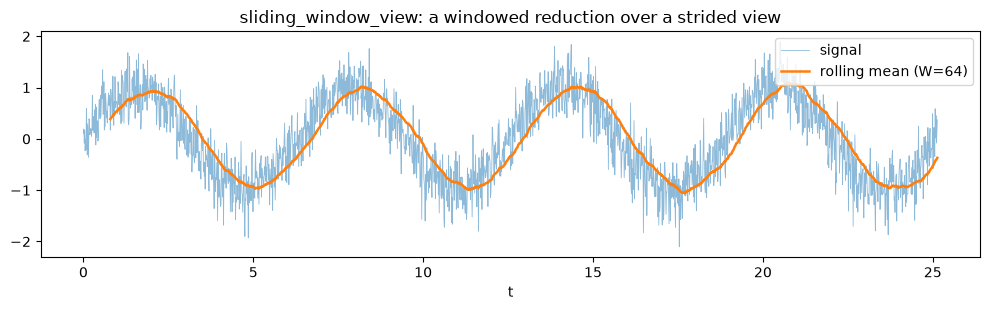

In [34]:
# Rolling mean of a noisy signal.
t_axis = np.linspace(0, 8 * np.pi, 2000)
long_signal = np.sin(t_axis) + 0.35 * rng.standard_normal(t_axis.size)

W = 64
moving_avg = sliding_window_view(long_signal, W).mean(axis=-1)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_axis, long_signal, lw=0.6, alpha=0.5, label="signal")
ax.plot(t_axis[W - 1:], moving_avg, lw=1.8, label=f"rolling mean (W={W})")
ax.set_xlabel("t")
ax.legend(loc="upper right")
ax.set_title("sliding_window_view: a windowed reduction over a strided view")
fig.tight_layout()
plt.show()

In [35]:
# The same trick in 2D gives image patches.
img = np.arange(7 * 8).reshape(7, 8)
patches = sliding_window_view(img, (3, 3))

print("img.shape:    ", img.shape)
print("patches.shape:", patches.shape)   # (5, 6, 3, 3)
print("patches[0, 0]:\n", patches[0, 0])

img.shape:     (7, 8)
patches.shape: (5, 6, 3, 3)
patches[0, 0]:
 [[ 0  1  2]
 [ 8  9 10]
 [16 17 18]]


Two warnings that belong with this tool:

- a window-based reduction is still $O(NW)$. A dedicated cumulative-sum algorithm is $O(N)$. A cheap
  view does not make an expensive algorithm cheap.
- `np.lib.stride_tricks.as_strided` lets you set strides arbitrarily. Wrong strides read memory
  outside the buffer, and overlapping writable views produce undefined results. Know that it exists.
  Prefer `sliding_window_view`. **Advanced does not mean reckless.**

---
## 8.2 Structured dtypes — reference depth

A structured dtype is an array of C-style records: a fixed layout with named fields. Useful for
binary formats, memory-mapped files, sensor and instrument records and C interoperability.

In [36]:
particle_dtype = np.dtype(
    [
        ("id", np.uint32),
        ("position", np.float32, (3,)),
        ("energy", np.float64),
        ("valid", np.bool_),
    ],
    align=True,   # apply C struct padding rules
)

particles = np.zeros(5, dtype=particle_dtype)
particles["id"] = np.arange(5)
particles["position"] = rng.standard_normal((5, 3)).astype(np.float32)
particles["energy"] = rng.uniform(0.5, 9.5, size=5)
particles["valid"][::2] = True

print("itemsize: ", particle_dtype.itemsize, "(sum of field sizes:",
      4 + 12 + 8 + 1, "-> the difference is padding)")
print("alignment:", particle_dtype.alignment)
for name, (dt, offset) in particle_dtype.fields.items():
    print(f"  {name:10s} offset={offset:3d} dtype={dt}")

print("\nparticles.strides:          ", particles.strides)
print("particles['energy'].strides:", particles["energy"].strides)

itemsize:  32 (sum of field sizes: 25 -> the difference is padding)
alignment: 8
  id         offset=  0 dtype=uint32
  position   offset=  4 dtype=('<f4', (3,))
  energy     offset= 16 dtype=float64
  valid      offset= 24 dtype=bool

particles.strides:           (32,)
particles['energy'].strides: (32,)


Note that `particles["energy"]` is a **view** with a stride equal to the record size. It is not
contiguous. That is exactly the array-of-structs layout, and it is the reason columnar formats
exist for analytics workloads. Do not infer that this is the right representation for a data table —
pandas and Arrow solve a different problem, with a columnar layout.

---
## 8.3 Masked arrays — reference depth

`numpy.ma` attaches a validity mask to otherwise ordinary array data, so reductions can skip
invalid entries without you inventing a sentinel value.

In [37]:
raw = np.array([1.0, 2.0, np.nan, 1000.0, 4.0])

masked = np.ma.masked_invalid(raw)                            # drop NaN/inf
masked = np.ma.masked_where((masked < -10) | (masked > 100), masked)  # drop outliers

print("raw:                        ", raw)
print("masked:                     ", masked)
print("mean ignoring masked values:", masked.mean())
print("count of valid entries:     ", masked.count())

raw:                         [   1.    2.   nan 1000.    4.]
masked:                      [1.0 2.0 -- -- 4.0]
mean ignoring masked values: 2.3333333333333335
count of valid entries:      3


---
## 9. Randomness: `Generator`, not the legacy global functions

`np.random.seed` and `np.random.rand` operate on one hidden global state. The current interface is an
explicit `Generator` object, which you pass around like any other dependency.

In [38]:
rng_a = np.random.default_rng(2026)
sample = rng_a.normal(loc=2.0, scale=3.0, size=100_000)

print(f"sample mean: {sample.mean():.4f}  (target 2.0)")
print(f"sample std:  {sample.std():.4f}  (target 3.0)")

# Reproducibility is a property of the seed, not of a global call order.
assert np.array_equal(
    np.random.default_rng(2026).normal(2.0, 3.0, 100_000), sample
)
print("re-seeded generator reproduces the sample exactly")

sample mean: 1.9995  (target 2.0)
sample std:  2.9917  (target 3.0)
re-seeded generator reproduces the sample exactly


In [39]:
# Independent streams: spawn children from one SeedSequence.
# This is the correct way to seed parallel workers - not seed+1, seed+2, ...
seed_seq = np.random.SeedSequence(2026)
child_rngs = [np.random.default_rng(s) for s in seed_seq.spawn(3)]

for i, r in enumerate(child_rngs):
    print(f"stream {i}: {r.standard_normal(4).round(4)}")

stream 0: [ 0.1107  0.1103  0.1994 -0.1923]
stream 1: [ 0.544   0.1155 -1.0814 -1.3754]
stream 2: [ 1.403  -1.332  -0.236   0.8275]


In [40]:
# Vectorized Monte Carlo: estimate pi with no Python loop.
rng_mc = np.random.default_rng(7)
xy = rng_mc.uniform(-1.0, 1.0, size=(300_000, 2))

inside = np.sum(xy * xy, axis=1) <= 1.0
pi_hat = 4.0 * inside.mean()

print(f"pi estimate: {pi_hat:.5f}   absolute error: {abs(pi_hat - np.pi):.5f}")

pi estimate: 3.14451   absolute error: 0.00291


---
## 9.1 Correctness before performance

Floating-point results that are algebraically equal are rarely bitwise equal. Compare with a
tolerance, and make silent numerical failures loud while you are debugging.

In [41]:
u = rng.standard_normal(1_000_000)

expected = np.sqrt(np.sum(u * u))
actual = np.linalg.norm(u)

print("exact equality:", actual == expected)
np.testing.assert_allclose(actual, expected, rtol=1e-10, atol=1e-12)
print("assert_allclose passed with rtol=1e-10")

exact equality: False
assert_allclose passed with rtol=1e-10


In [42]:
# Turn silent NaN/inf production into an exception while debugging.
with np.errstate(divide="raise", invalid="raise"):
    try:
        np.array([1.0]) / np.array([0.0])
    except FloatingPointError as exc:
        print("caught:", exc)

# Default behaviour outside the context manager: a warning and an inf.
print("outside errstate:", np.array([1.0]) / np.array([0.0]))

caught: divide by zero encountered in divide
outside errstate: [inf]


/tmp/ipykernel_2844786/1556131298.py:9: RuntimeWarning: divide by zero encountered in divide
  print("outside errstate:", np.array([1.0]) / np.array([0.0]))


---
## 9.2 Profiling: measure, do not guess

| Question | Tool |
|---|---|
| tiny local comparison | `%timeit` |
| reproducible, stable benchmark | `pyperf` |
| which line of a Python function is expensive | `line_profiler` |
| whole-program CPU profile | `%prun` or `cProfile` |
| accelerator timing | backend-aware events and profilers |

In [43]:
%timeit -r 5 -n 20 np.sqrt(np.sum(u * u))

571 μs ± 178 μs per loop (mean ± std. dev. of 5 runs, 20 loops each)


In [44]:
def slow_python_norm(x):
    total = 0.0
    for value in x:
        total += value * value
    return total ** 0.5


try:
    from line_profiler import LineProfiler
except ImportError:
    print("line_profiler is not installed - install it with: pip install line_profiler")
else:
    lp = LineProfiler()
    profiled = lp(slow_python_norm)
    profiled(u[:50_000])
    lp.print_stats()

Timer unit: 1e-09 s

Total time: 0.0149979 s
File: /tmp/ipykernel_2844786/1501727415.py
Function: slow_python_norm at line 1

Line #      Hits         Time  Per Hit   % Time  Line Contents
     1                                           def slow_python_norm(x):
     2         1        352.0    352.0      0.0      total = 0.0
     3     50001    6954340.0    139.1     46.4      for value in x:
     4     50000    8039656.0    160.8     53.6          total += value * value
     5         1       3525.0   3525.0      0.0      return total ** 0.5



For a benchmark you intend to quote to someone else, `%timeit` is not enough. `pyperf` calibrates the
run count, uses separate worker processes, records system metadata and warns you when the machine is
too unstable to trust. Run this in a terminal:

```bash
python -m pyperf timeit \
  -s 'import numpy as np; x = np.random.default_rng(0).normal(size=1_000_000)' \
  'np.sqrt(np.sum(x * x))'
```

### The optimization ladder

Work down this list in order. Most people start three steps too low.

```
correctness
   ↓
profile to find the real bottleneck
   ↓
better algorithm
   ↓
less data movement
   ↓
vectorize with NumPy / a library
   ↓
inspect copies, dtype, layout
   ↓
JIT or custom compiled kernel
   ↓
GPU or alternative backend
```

---
## 10. The same model on another backend

The interesting claim of this session is that the mental model transfers even when NumPy stops being
the thing that executes the code.

```
                 array code
                     │
                     ▼
        ┌────────────────────────┐
        │ shape + dtype + kernel │
        └────────────────────────┘
          │      │      │      │
        NumPy  CuPy   JAX   dpnp / ArrayFire
          │      │      │      │
         CPU   CUDA    XLA   SYCL / unified
```

### 10.1 A portable kernel

The Python array API standard defines a common surface that several libraries implement. Writing
against `__array_namespace__` is more honest than `import cupy as np`, because the latter implies a
compatibility that does not actually hold.

In [45]:
def portable_l2_normalize(x):
    """L2-normalize along the last axis, using whichever array namespace x belongs to."""
    namespace_method = getattr(x, "__array_namespace__", None)
    xp = namespace_method() if namespace_method is not None else np

    denom = xp.sqrt(xp.sum(x * x, axis=-1, keepdims=True))
    return x / denom


v = rng.standard_normal((4, 5))
out = portable_l2_normalize(v)

print("output shape:", out.shape)
print("row norms:   ", np.sqrt(np.sum(out * out, axis=-1)).round(12))

output shape: (4, 5)
row norms:    [1. 1. 1. 1.]


Keep portable kernels to a deliberately small vocabulary. Backend-specific NumPy features stay
backend-specific: CuPy does not provide equivalents for structured/record arrays or masked arrays,
and JAX deliberately changes mutation and dtype-promotion behaviour.

### 10.2 CuPy — the smallest migration

CuPy implements a large NumPy-shaped API over CUDA arrays. The code below is the same expression as
above with a different namespace and two explicit transfers.

In [46]:
x_np = rng.standard_normal(1_000_000).astype(np.float32)

try:
    import cupy as cp
except ImportError:
    cp = None
    print("CuPy: not installed - skipping.")

if cp is not None:
    x_gpu = cp.asarray(x_np)                      # host -> device
    y_gpu = cp.sqrt(cp.sum(x_gpu * x_gpu))
    y_cpu = cp.asnumpy(y_gpu)                     # device -> host

    print("CuPy result:  ", y_cpu)
    print("NumPy result: ", np.sqrt(np.sum(x_np * x_np)))

CuPy result:   1001.5089
NumPy result:  1001.5089


Then immediately dismantle the naive story that "GPU means faster". GPU calls are **asynchronous**,
so ordinary wall-clock timing around them measures dispatch, not execution. There are also one-time
CUDA context and kernel-compilation costs. The honest model of the pipeline is

$$T_{\text{GPU}} = T_{\text{host}\rightarrow\text{device}} + T_{\text{launch}} + T_{\text{kernel}} + T_{\text{device}\rightarrow\text{host}}$$

which is why `cupyx.profiler.benchmark` uses CUDA events rather than `time.perf_counter`.

### 10.3 JAX — the semantic contrast

JAX has a NumPy-inspired API, but its arrays are **immutable**. In-place assignment is replaced by a
functional update. This is the most useful backend to look at, because it breaks the assumption that
NumPy-like syntax implies NumPy-like semantics.

In [47]:
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    jax = None
    print("JAX: not installed - skipping.")

if jax is not None:
    print("JAX devices:", jax.devices())

    jx = jnp.asarray(np.arange(5, dtype=np.float32))
    # jx[2] = 99.0            # TypeError: JAX arrays are immutable
    jy = jx.at[2].set(99.0)   # functional update, returns a new array

    print("original:", jx)
    print("updated: ", jy)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


JAX devices: [CpuDevice(id=0)]
original: [0. 1. 2. 3. 4.]
updated:  [ 0.  1. 99.  3.  4.]


In [48]:
if jax is not None:
    def f(v):
        return jnp.sqrt(jnp.sum(v * v))

    x_jax = jnp.asarray(x_np)
    f_jit = jax.jit(f)

    f_jit(x_jax).block_until_ready()   # warm-up: this call pays for compilation

    t = min(timeit.repeat(lambda: f_jit(x_jax).block_until_ready(), number=20, repeat=5)) / 20
    print(f"jitted, after warm-up: {t * 1e6:.1f} us")
    print("NumPy equivalent:      "
          f"{min(timeit.repeat(lambda: np.sqrt(np.sum(x_np * x_np)), number=20, repeat=5)) / 20 * 1e6:.1f} us")

jitted, after warm-up: 103.4 us
NumPy equivalent:      296.6 us


`.block_until_ready()` is not optional. Without it you are timing dispatch. Without the warm-up call
you are timing the compiler.

**Discussion.** If the syntax looks like NumPy but mutation, compilation, device placement and timing
semantics have all changed, in what sense is it still the same programming model?

### 10.4 `dpnp` — oneAPI without writing SYCL

Intel's `dpnp` presents a NumPy-compatible API backed by SYCL/USM device memory. It is the shortest
path from this course into the oneAPI ecosystem, without a detour through DPC++ syntax.

```
C++ world                     Python world
DPC++ / SYCL                  dpnp
     ↓                             ↓
queues + kernels + USM        NumPy-like array operations
                                   ↓
                              SYCL / USM backend
```

In [51]:
try:
    import dpctl
    import dpnp
except ImportError:
    dpnp = None
    print("dpnp: not installed - skipping.")
else:
    if not dpctl.get_devices():
        dpnp = None
        print("dpnp: installed but no SYCL device available - skipping.")

if dpnp is not None:
    dx = dpnp.asarray(np.arange(10, dtype=np.float32))
    dy = dpnp.sqrt(dpnp.sum(dx * dx))

    print("device:", dx.sycl_device)
    print("dpnp result:", dpnp.asnumpy(dy))


dpnp: installed but no SYCL device available - skipping.


### 10.5 ArrayFire — the architectural contrast

ArrayFire is not CuPy with another name. It exposes unified CPU, CUDA, oneAPI and OpenCL backends
that can be selected at runtime, and it applies internal JIT analysis to fuse elementwise operations
and cut the number of temporary allocations.

It also closes the loop with Part 8 of this notebook. Its NumPy interoperability layer can borrow a
buffer without copying **only when the NumPy source is Fortran-contiguous**.

> Why should an accelerator library care whether your NumPy array is C-contiguous or F-contiguous?

After Part 8 you can answer that.

In [59]:
import array

try:
    import arrayfire as af
except ImportError:
    af = None
    print("ArrayFire: not installed - skipping.")

if af is not None:
    backends = []
    for bt in (af.BackendType.cpu, af.BackendType.cuda, af.BackendType.opencl, af.BackendType.oneapi):
        try:
            af.set_backend(bt)
            af.sum(af.randu((2, 2)))   # set_backend only loads the .so; this proves it runs
            backends.append(bt.name)
        except Exception:  # noqa
            pass
    if "cuda" in backends:
        af.set_backend(af.BackendType.cuda)
    print("available backends:", backends)
    print("active backend:", af.get_backend().backend_type, "| devices:", af.get_device_count())

    x_f = np.asfortranarray(rng.normal(size=(100, 80)).astype(np.float32))
    print("F-contiguous:", x_f.flags.f_contiguous)

    # no ndarray interop in 0.1.0 - copy through a host buffer.
    # ArrayFire is column-major, so hand it F-order data.
    ax = af.Array(array.array("f", x_f.ravel(order="F")), shape=x_f.shape)
    print("arrayfire array:", ax.shape, ax.dtype)

available backends: ['cpu', 'cuda']
active backend: BackendType.cuda | devices: 1
F-contiguous: True
arrayfire array: (100, 80) float32


---
## 10.6 Designing a fair backend benchmark

Benchmark

$$f(X) = X^\top\bigl(X - \operatorname{mean}(X, \text{axis}=0)\bigr)$$

on NumPy and on any backend available to you. A result is meaningless unless you state all of the
following alongside it:

```
shape
dtype
hardware
library / backend version
host<->device transfer included?
JIT compilation included?
synchronization method
warm-up performed?
number of repetitions
numerical tolerance used to check agreement
```

Reporting "which number is smaller" without that list is not a benchmark. It is an anecdote.

In [53]:
def centered_gram(X, xp=np):
    return X.T @ (X - xp.mean(X, axis=0, keepdims=True))


X_bench = rng.standard_normal((4000, 256)).astype(np.float32)

t = min(timeit.repeat(lambda: centered_gram(X_bench), number=3, repeat=5)) / 3

print(f"shape={X_bench.shape}  dtype={X_bench.dtype}")
print(f"backend=numpy {np.__version__}  transfer=n/a  jit=no  warm-up=n/a")
print(f"best of 5 x 3 repetitions: {t * 1e3:.2f} ms")

shape=(4000, 256)  dtype=float32
backend=numpy 2.5.3  transfer=n/a  jit=no  warm-up=n/a
best of 5 x 3 repetitions: 5.08 ms


---
## Exit challenge

For a batch of images `images` with shape `(N, H, W, 3)` and `channel_scales` with shape `(3,)`:

```python
scaled = images * channel_scales
every_second = images[::2]
selected = images[[7, 1, 9]]
```

1. For each of the three lines, state whether a copy is made and why.
2. Then answer: when would you move this computation to CuPy, JAX, `dpnp` or ArrayFire?

In [54]:
N, H, W = 12, 64, 48
images = rng.random((N, H, W, 3), dtype=np.float32)
channel_scales = np.array([0.9, 1.0, 1.1], dtype=np.float32)

scaled = images * channel_scales
every_second = images[::2]
selected = images[[7, 1, 9]]

for name, arr in [("scaled", scaled), ("every_second", every_second), ("selected", selected)]:
    print(f"{name:13s} shape={str(arr.shape):20s} "
          f"shares_memory={np.shares_memory(images, arr)}")

scaled        shape=(12, 64, 48, 3)      shares_memory=False
every_second  shape=(6, 64, 48, 3)       shares_memory=True
selected      shape=(3, 64, 48, 3)       shares_memory=False


<details>
<summary><b>Answers</b></summary>

```
scaled        new array. Broadcasting does not tile channel_scales, but the
              elementwise product still has to be written somewhere.

every_second  basic slicing -> a view. No element is copied, only the stride
              along axis 0 is doubled.

selected      advanced indexing -> a copy. The requested rows cannot be
              described by any single set of strides.
```

**When to move to another backend.** Not "when you have a GPU". The honest answer is:

after profiling has identified a real bottleneck, when the backend supports the semantics the code
actually needs, when the workload has enough parallel numerical work to fill the device, and when the
data can stay on the accelerator long enough to amortize transfer, launch and compilation overhead.
</details>

---
## Summary

The progression of this session, in one column:

```
What is an ndarray really?
        ↓
How does shape determine computation?
        ↓
Why is NumPy fast?
        ↓
When does vectorization become expensive?
        ↓
Am I sharing memory or copying it?
        ↓
How does layout reach BLAS and native code?
        ↓
How do I measure rather than guess?
        ↓
What changes when the array lives on a device?
        ↓
Why do CuPy, JAX, dpnp and ArrayFire look familiar?
```

The closing question, which was also the opening one:

> If an array is a representation plus an execution model, does that execution model have to be
> NumPy on a CPU?

### Further reading

- NumPy internals: [Memory layout of ndarray](https://numpy.org/doc/stable/reference/arrays.ndarray.html)
- [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) and [Indexing](https://numpy.org/doc/stable/user/basics.indexing.html)
- [`numpy.lib.stride_tricks.sliding_window_view`](https://numpy.org/doc/stable/reference/generated/numpy.lib.stride_tricks.sliding_window_view.html)
- [Random sampling with `Generator`](https://numpy.org/doc/stable/reference/random/generator.html)
- [Python array API standard](https://data-apis.org/array-api/latest/)
- [CuPy performance best practices](https://docs.cupy.dev/en/stable/user_guide/performance.html), [JAX benchmarking](https://docs.jax.dev/en/latest/faq.html)